[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gamayos/agh-habitat-pl/blob/main/notebooks/ml4sa2-lab1-20261121.ipynb)

## WTKSTES.IIi2K.17922.24: Machine Learning for Space Applications
# Lab 1: Setup, authentication, data access

1.   Google Satellite Embeddings
2.   CORINE 2018

## Requirements:

- Google account (provide Google email to instructor)
- Github account
- Github access token

## Setup and authentication steps:

- Clone Github repository
- Check out template repository into Google Colab
- Generate Github access token
- Setup GITHUB_TOKEN in Secrets
- Varify access to Google Earth Engine
- Visualize datasets

## Objectives:

1. Define two AOIs for well distinct, well defined surface classes

2. Download Google Sat Embeddings for the defined AOIs

3. Apply unsupervised clustering of the embeddings using 4 different clustering methods

4. Visualise and document the results

In [1]:
%cd /content
!rm -rf agh-habitat-pl
!git clone https://github.com/gamayos/agh-habitat-pl.git
!pip -q install earthengine-api geemap
%cd agh-habitat-pl

/content
Cloning into 'agh-habitat-pl'...
remote: Enumerating objects: 110, done.
remote: Counting objects: 100% (41/41), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 110 (delta 32), reused 30 (delta 30), pack-reused 69 (from 1)
Receiving objects: 100% (110/110), 57.96 KiB | 2.63 MiB/s, done.
Resolving deltas: 100% (45/45), done.
/content/agh-habitat-pl


In [7]:
from google.colab import userdata
import sys
import ee
import os
os.environ["USE_FOLIUM"] = "1"  # must be set before geemap is first imported
import geemap.foliumap as geemap  # folium/Leaflet maps: no Google Maps key lookup
sys.path.append('/content/agh-habitat-pl/src')

ee.Authenticate()
ee.Initialize(project='wtk-sar')

In [8]:
import ipywidgets as widgets
import habitat_pl.viz.corine as corine
import importlib

importlib.reload(corine)

region = (ee.FeatureCollection('FAO/GAUL/2015/level1')
          .filter(ee.Filter.eq('ADM1_NAME', 'Malopolske'))
          .geometry())

# Annual Satellite Embedding (example: 2021)
emb = (ee.ImageCollection('GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL')
       .filterDate('2021-01-01','2022-01-01')
       .filterBounds(region)
       .mosaic()
       .clip(region))

# Visualize (pseudo-RGB from embedding bands)
m = geemap.Map(basemap='ROADMAP')
m.centerObject(region, 8)
m.addLayer(emb, {'min':-0.3,'max':0.3,'bands':['A01','A16','A09']}, 'Embeddings 2021')

# Loads CORINE Land Cover 2018 raster (44 classes, 100 m resolution).
clc = ee.Image('COPERNICUS/CORINE/V20/100m/2018').select('landcover').clip(region)

# Remaps CORINE class codes (111…523) to sequential indices (1…44).
clc_idx = clc.remap(corine.codes, list(range(1, len(corine.codes)+1))).rename('landcover_idx')

# Adds the CORINE raster to the map, colored according to EEA’s palette
m.addLayer(clc_idx, corine.vis, 'CORINE 2018')

# Creates a scrollable legend showing all 44 class names with their corresponding colors.
legend = m.add_legend(title="CORINE Land Cover 2018", legend_dict=corine.legend_dict)

m

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level1! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level1

  warnings.warn(warning, category=DeprecationWarning)


In [10]:
slaskie = (
    ee.FeatureCollection('FAO/GAUL/2015/level1')
    .filter(ee.Filter.eq('ADM1_NAME', 'Slaskie'))
    .geometry()
)

katowice_bbox = ee.Geometry.Rectangle([18.85, 50.15, 19.25, 50.36])
region = slaskie.intersection(katowice_bbox, maxError=100)

In [13]:
# Annual Satellite Embedding (example: 2021)
emb = (ee.ImageCollection('GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL')
       .filterDate('2021-01-01','2022-01-01')
       .filterBounds(region)
       .mosaic()
       .clip(region))

# Visualize (pseudo-RGB from embedding bands)
m = geemap.Map(basemap='ROADMAP')
m.centerObject(region, 8)
m.addLayer(emb, {'min':-0.3,'max':0.3,'bands':['A01','A16','A09']}, 'Embeddings 2021')

# Loads CORINE Land Cover 2018 raster (44 classes, 100 m resolution).
clc = ee.Image('COPERNICUS/CORINE/V20/100m/2018').select('landcover').clip(region)

# Remaps CORINE class codes (111…523) to sequential indices (1…44).
clc_idx = clc.remap(corine.codes, list(range(1, len(corine.codes)+1))).rename('landcover_idx')

# Adds the CORINE raster to the map, colored according to EEA’s palette
m.addLayer(clc_idx, corine.vis, 'CORINE 2018')

# Creates a scrollable legend showing all 44 class names with their corresponding colors.
legend = m.add_legend(title="CORINE Land Cover 2018", legend_dict=corine.legend_dict)

m

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


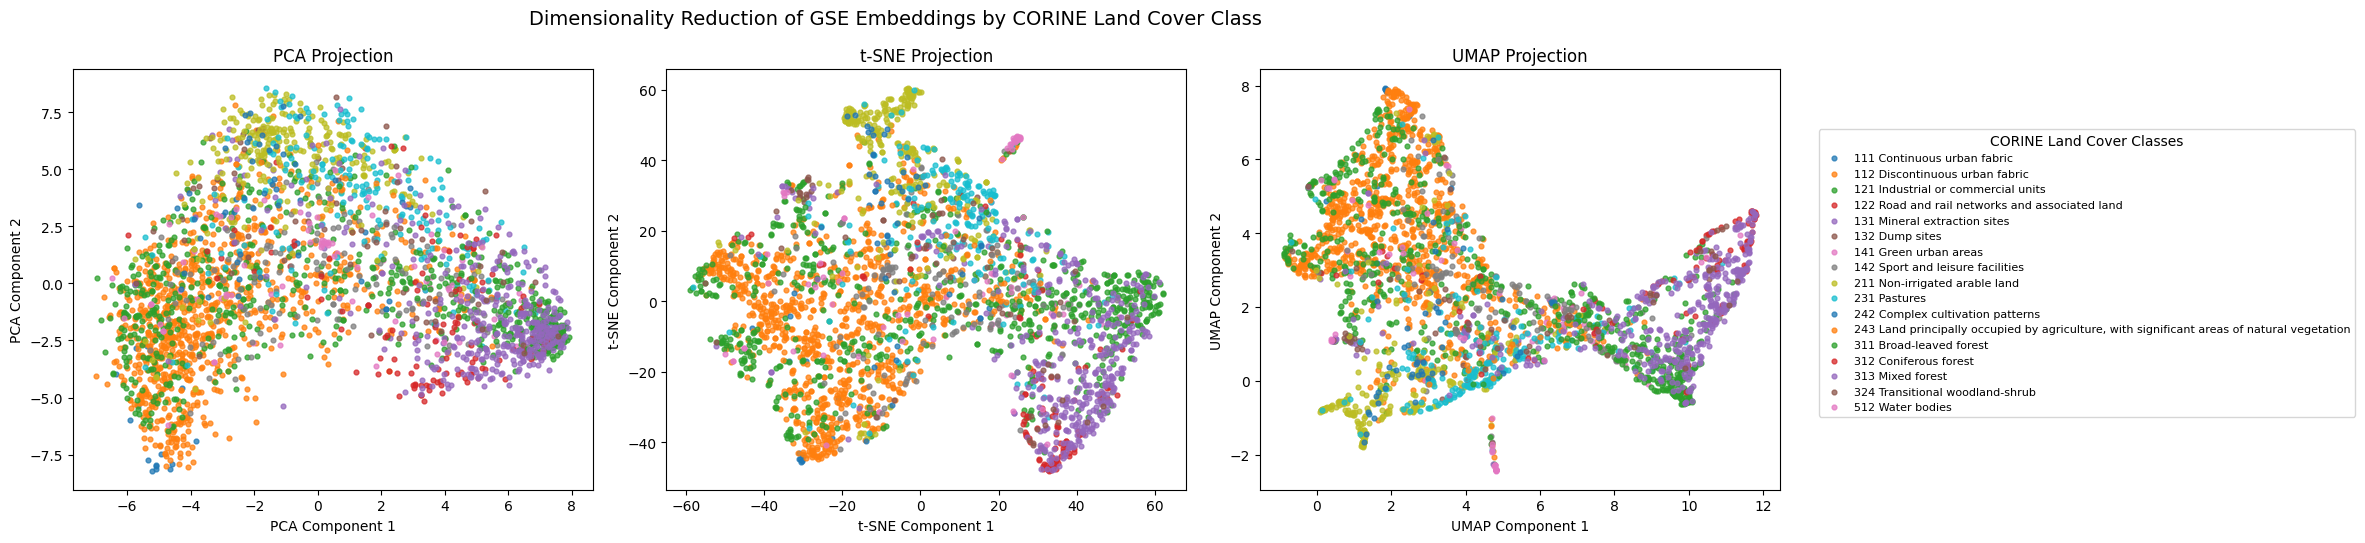

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# !pip -q install umap-learn
import umap

# 1. Combine GSE embeddings with CORINE labels
samples_img = emb.addBands([clc_idx, clc.rename('corine_code')])

# 2. Sample pixels inside the target region (100 m scale matching CORINE)
samples_fc = samples_img.sample(
    region=region,
    scale=100,
    numPixels=3000,
    seed=42,
    geometries=False,
)

rows = [f['properties'] for f in samples_fc.getInfo()['features']]
df = pd.DataFrame(rows).dropna()

# Embedding feature columns (e.g., A00..A63)
feature_cols = [
    c
    for c in df.columns
    if c not in ('landcover_idx', 'corine_code')
    and pd.api.types.is_numeric_dtype(df[c])
]

df['landcover_idx'] = df['landcover_idx'].astype(int)
df['corine_code'] = df['corine_code'].astype(int)

# Map index 1..44 to class names from legend_dict
if hasattr(corine, 'legend_dict') and corine.legend_dict:
  keys = list(corine.legend_dict.keys())
  if isinstance(keys[0], str):
    idx_to_label = {i + 1: name for i, name in enumerate(keys)}
  else:
    idx_to_label = corine.legend_dict
  df['corine_label'] = (
      df['landcover_idx']
      .map(idx_to_label)
      .fillna('CORINE ' + df['corine_code'].astype(str))
  )
else:
  df['corine_label'] = 'CORINE ' + df['corine_code'].astype(str)

# Filter out rare classes with too few samples
counts = df['corine_label'].value_counts()
valid_classes = counts[counts >= 15].index
df_sub = df[df['corine_label'].isin(valid_classes)].copy()

# 3. Standardize features and run dimensionality reduction
X = StandardScaler().fit_transform(df_sub[feature_cols].to_numpy())
y = df_sub['corine_label'].to_numpy()

perp = min(30, max(5, len(df_sub) // 10))
coords = {
    'PCA': PCA(n_components=2, random_state=42).fit_transform(X),
    't-SNE': TSNE(
        n_components=2,
        perplexity=perp,
        init='pca',
        learning_rate='auto',
        random_state=42,
    ).fit_transform(X),
    'UMAP': umap.UMAP(
        n_components=2, n_neighbors=15, min_dist=0.1, random_state=42
    ).fit_transform(X),
}

# 4. Plot 2D projections annotated with CORINE labels
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
fig.suptitle(
    'Dimensionality Reduction of GSE Embeddings by CORINE Land Cover Class',
    fontsize=14,
)

for ax, (method, emb_2d) in zip(axes, coords.items()):
  for label in sorted(np.unique(y)):
    mask = y == label
    ax.scatter(
        emb_2d[mask, 0],
        emb_2d[mask, 1],
        label=label,
        s=12,
        alpha=0.75,
    )
  ax.set_title(f'{method} Projection')
  ax.set_xlabel(f'{method} Component 1')
  ax.set_ylabel(f'{method} Component 2')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='center left',
    bbox_to_anchor=(1.01, 0.5),
    title='CORINE Land Cover Classes',
    fontsize=8,
)
plt.tight_layout()
plt.savefig('gse_dim_reduction_corine_en.png', dpi=200, bbox_inches='tight')
plt.show()